# Backpropagation

## 1. Lead-in

### 1.1 Idea 1: Derive the gradient on paper

problems: 
1. non-modular
2. tedious and complex

### 1.2 Idea 2: Computational Graph



## 2. Backpropagation: structure

在computation graph上进行自动微分。

### 2.1 基本结构
1. backward pass 计算函数值
2. forward pass 计算梯度
3. chain rule 传播梯度：upstream gradient, downstream gradient, local gradient

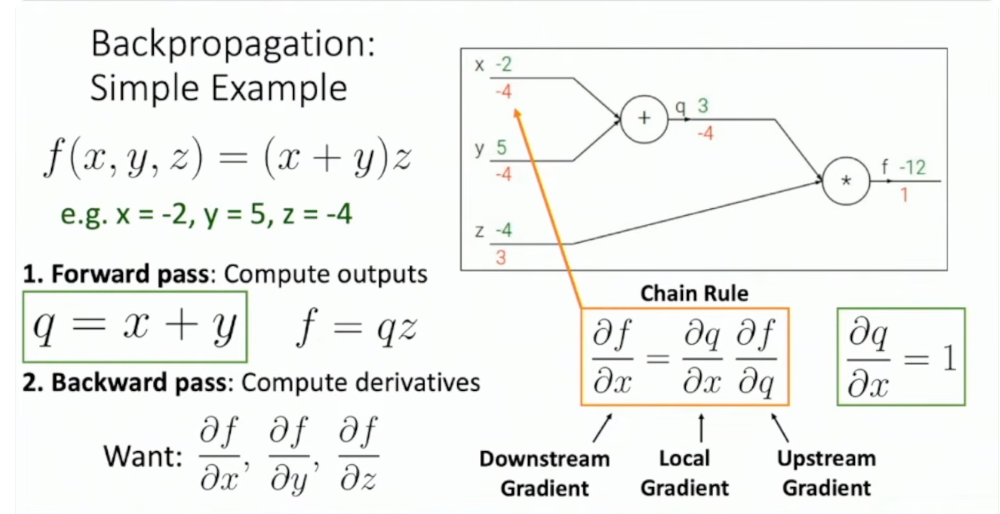

### 2.2 优点
modular, 且可以自定义运算（eg. sigmoid function）
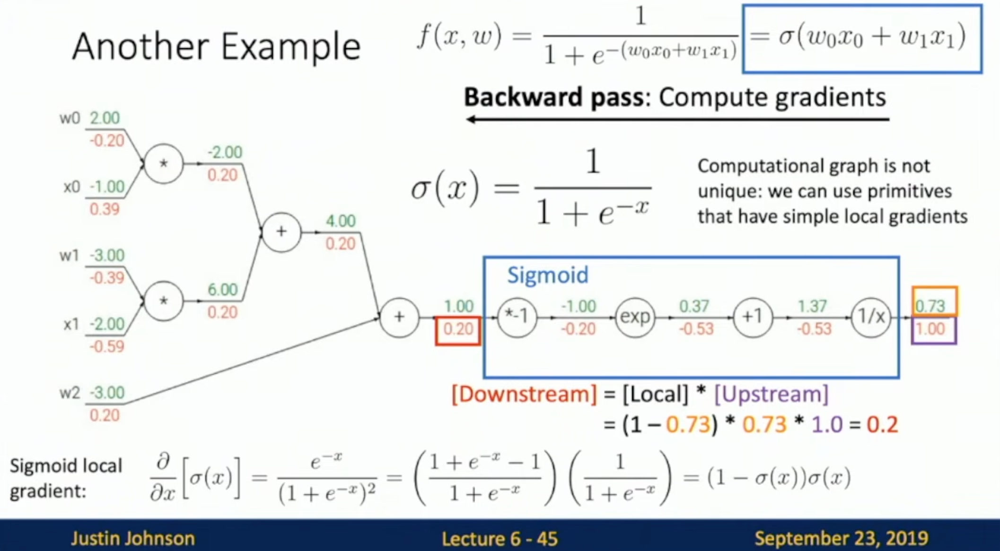

### 2.3 Patterns in Gradient Flows
1. add gate
2. copy gate(和add gate是dual的)
3. mul gate
4. max gate: 有梯度消失的问题
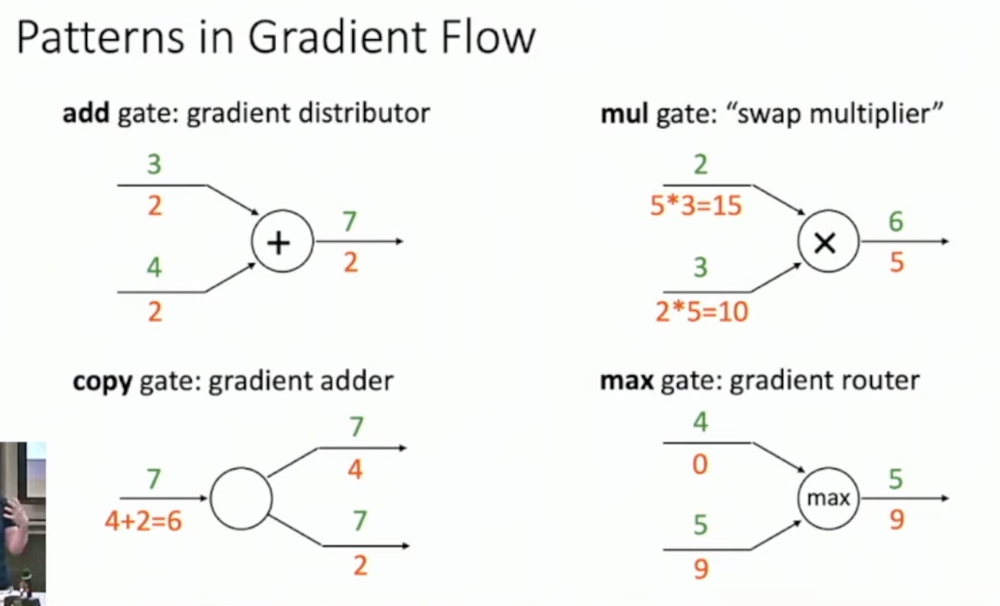

## 3 Backprop Implementation
### 3.1 手写：根据forward反着对照写backward
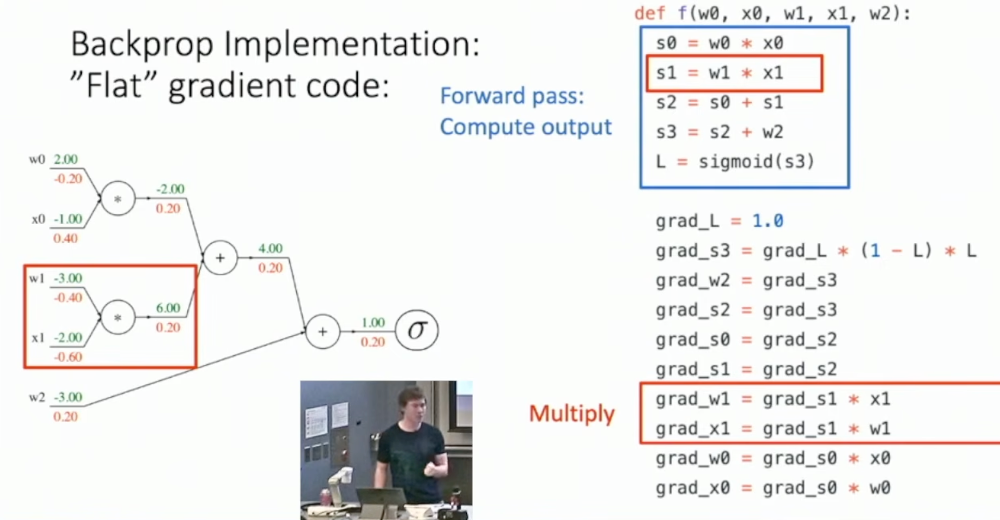

### 3.2 api call
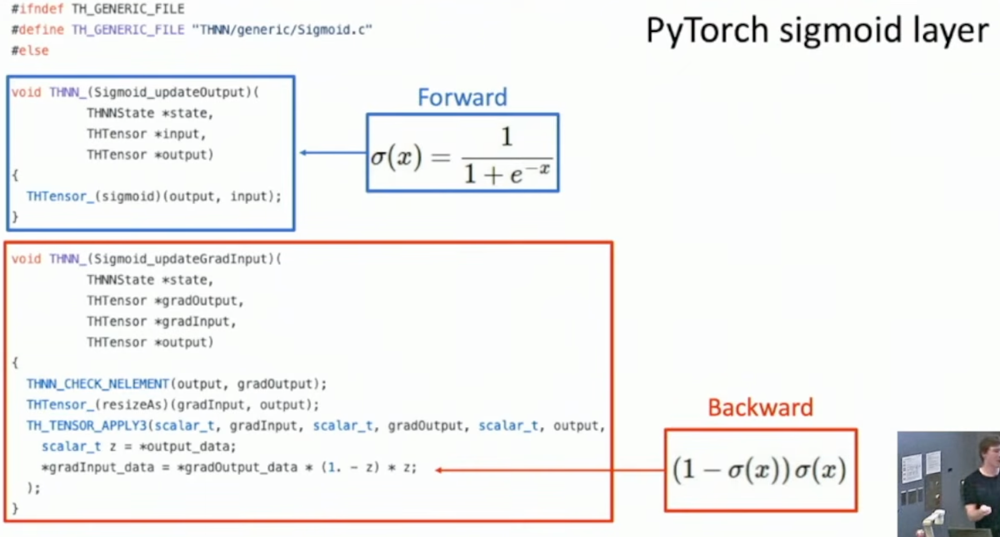

In [ ]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import torch
class Multiply(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, y):
        ctx.save_for_backward(x, y) #存储函数值
        return x * y

    @staticmethod
    def backward(ctx, grad_z):
        x,y = ctx.saved_tensors #提取函数值
        grad_x = y * grad_z
        grad_y = x * grad_z
        return grad_x, grad_y

## 4. Backprop with vectors and matrices

$$\text regular \rightarrow \text Gradient \rightarrow \text Jacobian$$
$$\mathbb{R} \rightarrow \mathbb{R}, \mathbb{R}^n \rightarrow \mathbb{R}, \mathbb{R}^n \rightarrow \mathbb{R}^m$$
值得注意的是，数据不止一条，因此即使是regular backprop，local gradient也是一个向量，而不是一个数。gradient的是一个矩阵，Jacobian的是一个张量。

### 4.1 Regular Backprop
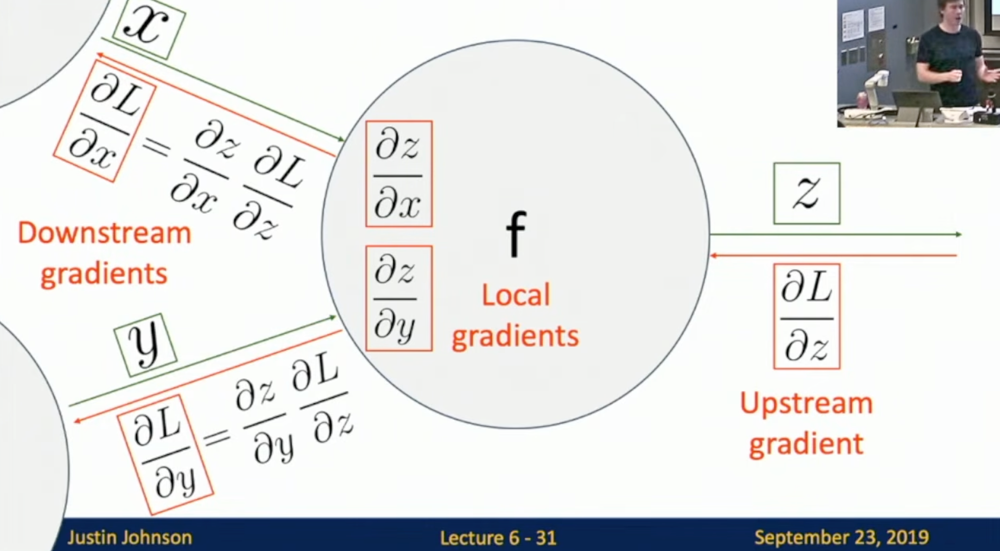

标量运算（同时处理多个样本）：z_i = x_i ** 2

每个样本独立计算，给定上游梯度 dz，dx = dz * 2x。

In [ ]:
import torch

torch.set_printoptions(precision=4, sci_mode=False)

x = torch.tensor([1.0, -2.0, 3.0], dtype=torch.float64, requires_grad=True)
z = x ** 2
dz = torch.tensor([1.0, 0.5, -1.0], dtype=x.dtype)
dx_manual = dz * 2 * x.detach()
dx_auto, = torch.autograd.grad(z, x, grad_outputs=dz)
torch.testing.assert_close(dx_manual, dx_auto)
print("4.1 dx:", dx_manual)


### 4.2 Backprop with Vectors
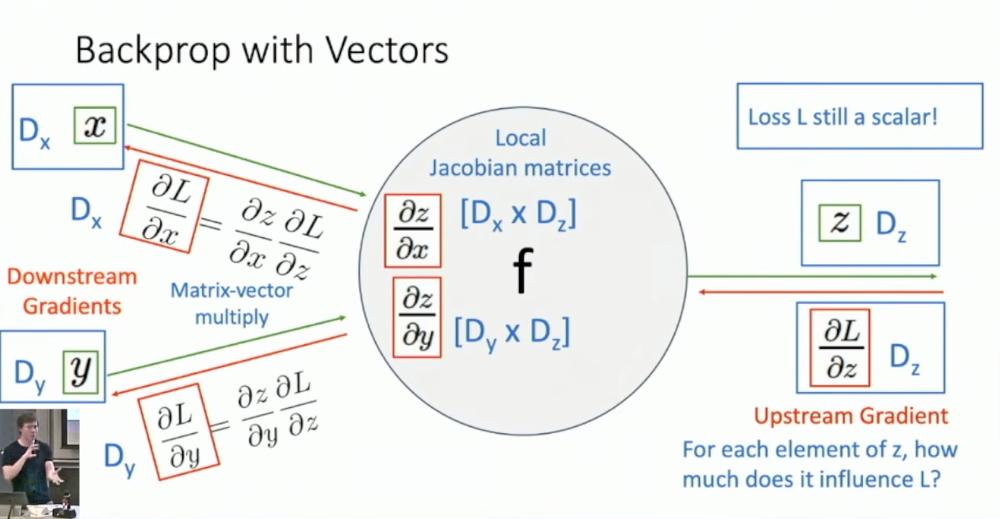

向量运算：y = ReLU(x)

Jacobian 是对角矩阵；用逐元素乘法计算 J.T @ dy，无需构造 J。

In [ ]:
x = torch.tensor([-2.0, -0.5, 1.0, 3.0], dtype=torch.float64, requires_grad=True)
y = torch.relu(x)
dy = torch.tensor([1.0, 2.0, 3.0, 4.0], dtype=x.dtype)
dx_manual = dy * (x.detach() > 0)
dx_auto, = torch.autograd.grad(y, x, grad_outputs=dy)
torch.testing.assert_close(dx_manual, dx_auto)
print("4.2 dx:", dx_manual)


### 4.3 Backprop with Matrices
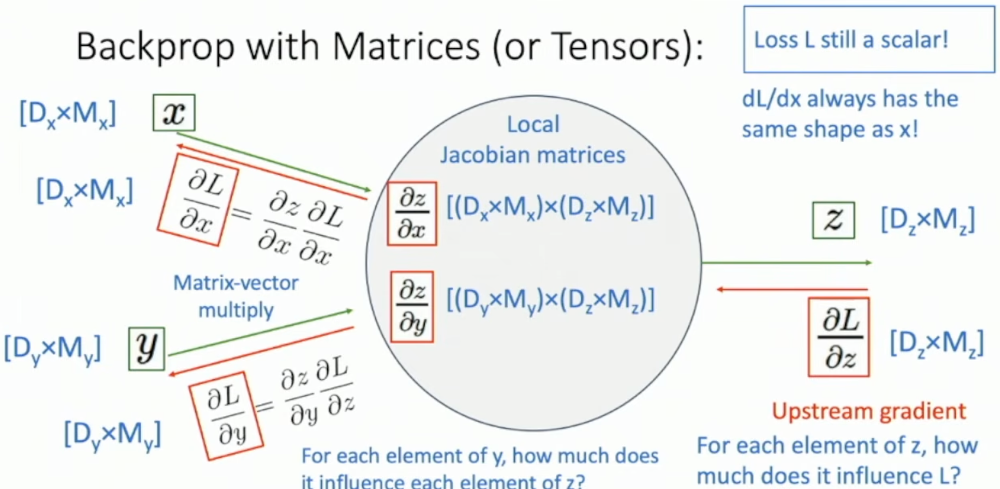

矩阵运算：Y = X @ W + b

X: (N, D)，W: (D, M)，b: (M,)，Y: (N, M)。

用平方误差的均值作为标量损失，先求 dY，再向 X、W、b 传播。

In [ ]:
generator = torch.Generator().manual_seed(42)
N, D, M = 2, 3, 4
X = torch.randn(N, D, generator=generator, dtype=torch.float64, requires_grad=True)
W = torch.randn(D, M, generator=generator, dtype=torch.float64, requires_grad=True)
b = torch.randn(M, generator=generator, dtype=torch.float64, requires_grad=True)
target = torch.randn(N, M, generator=generator, dtype=torch.float64)
Y = X @ W + b
loss = ((Y - target) ** 2).mean()

with torch.no_grad():
    dY = 2 * (Y - target) / Y.numel()
    dX = dY @ W.T
    dW = X.T @ dY
    db = dY.sum(dim=0)  # b 在样本维广播，反向传播时沿该维求和。

auto_grads = torch.autograd.grad(loss, (X, W, b))
for name, manual, automatic in zip(("dX", "dW", "db"), (dX, dW, db), auto_grads):
    torch.testing.assert_close(manual, automatic)
    print(f"4.3 {name} (shape={tuple(manual.shape)}):\n{manual}")


### 4.4 针对4.2，4.3 implementation的说明
在真实的实现中，我们一般不直接用显式的矩阵乘法（jacobian是sparse的，无谓开销非常大）

上述运算直接计算向量-Jacobian 积（VJP），不创建完整 Jacobian。

In [ ]:
print("全部手写梯度与 PyTorch 自动微分一致。")


## 5. Another View
### 5.1 Reverse Mode Automatic Differentiation
$$X_0 \rightarrow X_1 \rightarrow X_2 \rightarrow X_3 \rightarrow X_4 \rightarrow Loss$$
compute grad of scalar output respect to all vectors inputs

### 5.2 Forward Mode Automatic Differentiation
$$a\rightarrow X_1 \rightarrow X_2 \rightarrow X_3 \rightarrow X_4 $$
此时用forward会更好，forward不需要matrix to matrix，只需要matrix to vector。但在pytorch里面没有相应api，可以通过调用两次reverse api实现（inefficient）。

### 5.3 Backprop: Higher-Order Derivatives
可以非常好的计算高阶导数（解决张量不好计算的问题，结合vector的泰勒展开问题）
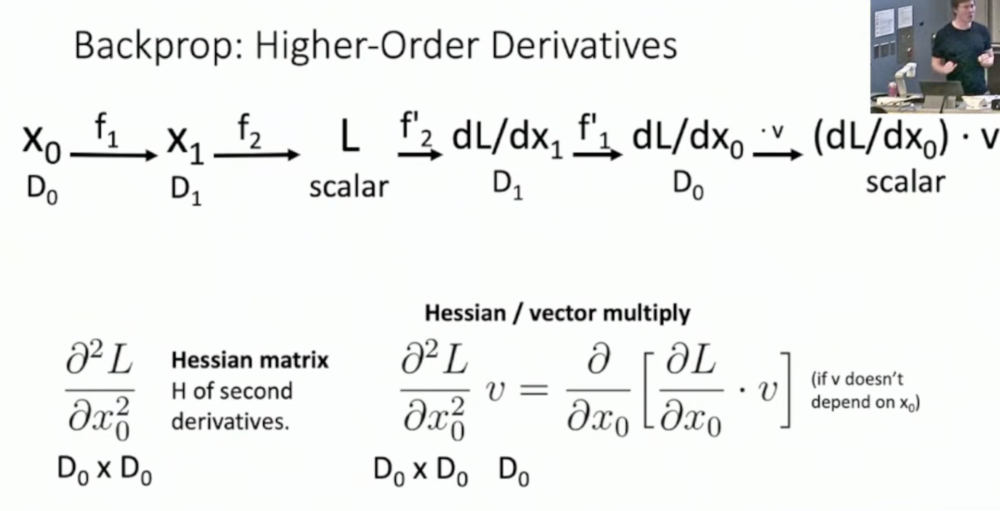